In [2]:
%pip install opencv-python

   ---------------------------------------- 0.0/48.0 MB ? eta -:--:--
   ---------------------------------------- 0.0/48.0 MB ? eta -:--:--
   ---------------------------------------- 0.0/48.0 MB 487.6 kB/s eta 0:01:39
   ---------------------------------------- 0.1/48.0 MB 1.1 MB/s eta 0:00:44
   ---------------------------------------- 0.3/48.0 MB 1.7 MB/s eta 0:00:28
   ---------------------------------------- 0.5/48.0 MB 2.7 MB/s eta 0:00:18
    --------------------------------------- 1.0/48.0 MB 4.5 MB/s eta 0:00:11
    --------------------------------------- 1.0/48.0 MB 4.5 MB/s eta 0:00:11
    --------------------------------------- 1.0/48.0 MB 3.1 MB/s eta 0:00:16
   - -------------------------------------- 1.7/48.0 MB 4.4 MB/s eta 0:00:11
   -- ------------------------------------- 2.6/48.0 MB 6.1 MB/s eta 0:00:08
   --- ------------------------------------ 3.7/48.0 MB 7.8 MB/s eta 0:00:06
   --- ------------------------------------ 4.5/48.0 MB 8.7 MB/s eta 0:00:05
   ---- ---


[notice] A new release of pip is available: 24.0 -> 26.3
[notice] To update, run: python.exe -m pip install --upgrade pip


In [5]:
%pip install --upgrade pip

  Using cached pip-26.3-py3-none-any.whl.metadata (4.6 kB)
Using cached pip-26.3-py3-none-any.whl (2.0 MB)
  Attempting uninstall: pip
    Found existing installation: pip 24.0
    Uninstalling pip-24.0:
      Successfully uninstalled pip-24.0
Note: you may need to restart the kernel to use updated packages.


In [6]:
# 1. Imports and environment check
from pathlib import Path
import os
import numpy as np
import matplotlib.pyplot as plt
import tensorflow as tf

print("TensorFlow:", tf.__version__)
print("NumPy:", np.__version__)

try:
    import cv2
    print("OpenCV:", cv2.__version__)
except ImportError:
    raise ImportError(
        "OpenCV is required for image segmentation. Install it in this Jupyter kernel "
        "using: %pip install opencv-python"
    )

print("Available devices:", tf.config.list_physical_devices())


TensorFlow: 2.21.0
NumPy: 2.5.4
OpenCV: 5.1.0
Available devices: [PhysicalDevice(name='/physical_device:CPU:0', device_type='CPU')]


In [8]:
from pathlib import Path

ROOT = Path(r"D:\RetailMind-AI")

print("Project folders:")
for item in ROOT.iterdir():
    if item.is_dir():
        print("\n📁", item.name)

print("\nAll saved model files:")

for file in ROOT.rglob("*"):
    if file.is_file() and file.suffix.lower() in [".keras", ".h5", ".hdf5"]:
        print(file)

Project folders:

📁 .git

📁 Data

📁 Models

📁 Notebooks

📁 Src

All saved model files:
D:\RetailMind-AI\Models\fashion_cnn.keras


In [10]:
# 2. Locate the project folder and trained Day 07 model

from pathlib import Path

ROOT = Path(r"D:\RetailMind-AI")

MODEL_PATH = ROOT / "Models" / "fashion_cnn.keras"

if not MODEL_PATH.exists():
    raise FileNotFoundError(f"Model not found: {MODEL_PATH}")

print("Project root:", ROOT)
print("Model path:", MODEL_PATH)
print("Model exists:", MODEL_PATH.exists())

Project root: D:\RetailMind-AI
Model path: D:\RetailMind-AI\Models\fashion_cnn.keras
Model exists: True


In [11]:
# 3. Load the trained VGG16 classifier
model = tf.keras.models.load_model(MODEL_PATH)
print("Model loaded successfully.")
model.summary()


Model loaded successfully.


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━┓
┃ Layer (type)                  ┃ Output Shape          ┃      Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━┩
│ image_augmentation            │ (None, 28, 28, 1)     │            0 │
│ (Sequential)                  │                       │              │
├───────────────────────────────┼───────────────────────┼──────────────┤
│ conv2d (Conv2D)               │ (None, 28, 28, 32)    │          320 │
├───────────────────────────────┼───────────────────────┼──────────────┤
│ max_pooling2d (MaxPooling2D)  │ (None, 14, 14, 32)    │            0 │
├───────────────────────────────┼───────────────────────┼──────────────┤
│ conv2d_1 (Conv2D)             │ (None, 14, 14, 64)    │       18,496 │
├───────────────────────────────┼───────────────────────┼──────────────┤
│ max_pooling2d_1               │ (None, 7, 7, 64)      │            0 │
│ (MaxPooling2D)                │                       │              │
├───────────────────────────────┼───────────────────────┼──────────────┤
│ conv2d_2 (Conv2D)             │ (None, 7, 7, 128)     │       73,856 │
├───────────────────────────────┼───────────────────────┼──────────────┤
│ max_pooling2d_2               │ (None, 3, 3, 128)     │            0 │
│ (MaxPooling2D)                │                       │              │
├───────────────────────────────┼───────────────────────┼──────────────┤
│ flatten (Flatten)             │ (None, 1152)          │            0 │
├───────────────────────────────┼───────────────────────┼──────────────┤
│ dense (Dense)                 │ (None, 128)           │      147,584 │
├───────────────────────────────┼───────────────────────┼──────────────┤
│ dropout (Dropout)             │ (None, 128)           │            0 │
├───────────────────────────────┼───────────────────────┼──────────────┤
│ dense_1 (Dense)               │ (None, 10)            │        1,290 │
└───────────────────────────────┴───────────────────────┴──────────────┘

 Total params: 724,640 (2.76 MB)

 Trainable params: 241,546 (943.54 KB)

 Non-trainable params: 0 (0.00 B)

 Optimizer params: 483,094 (1.84 MB)

Input image shape: (28, 28, 1)
Input batch shape: (1, 28, 28, 1)
True label: Ankle boot
Predicted label: Ankle boot
Confidence: 99.96 %


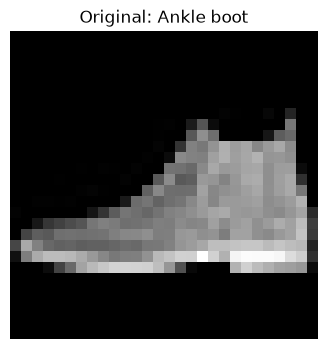

In [13]:

# 4. Load Fashion-MNIST test data and prepare one image

(x_train, y_train), (x_test, y_test) = tf.keras.datasets.fashion_mnist.load_data()

CLASS_NAMES = [
    "T-shirt/top", "Trouser", "Pullover", "Dress", "Coat",
    "Sandal", "Shirt", "Sneaker", "Bag", "Ankle boot"
]

# Prepare image according to our trained CNN input shape
def prepare_fashion_image(gray_image):

    gray_image = gray_image.astype("float32") / 255.0

    # Add channel dimension: (28, 28) -> (28, 28, 1)
    image = np.expand_dims(gray_image, axis=-1)

    return image

SAMPLE_INDEX = 0

image = prepare_fashion_image(x_test[SAMPLE_INDEX])

input_batch = np.expand_dims(image, axis=0)

print("Input image shape:", image.shape)
print("Input batch shape:", input_batch.shape)

# Predict
prediction = model.predict(input_batch, verbose=0)

predicted_class = int(np.argmax(prediction[0]))
true_class = int(y_test[SAMPLE_INDEX])

print("True label:", CLASS_NAMES[true_class])
print("Predicted label:", CLASS_NAMES[predicted_class])
print("Confidence:", round(float(np.max(prediction[0])) * 100, 2), "%")

plt.figure(figsize=(4, 4))
plt.imshow(image.squeeze(), cmap="gray")
plt.title(f"Original: {CLASS_NAMES[true_class]}")
plt.axis("off")
plt.show()


## Part A — Grad-CAM (model explainability)

Grad-CAM uses the gradients of the predicted class with respect to the final convolutional feature maps. It produces a heatmap showing which image regions contributed most to the prediction.

For VGG16, the final convolutional layer is usually `block5_conv3`.


In [14]:
# 5. Find the final convolutional layer
# The VGG16 network may be nested inside the outer classifier model.
def find_layer_recursive(layer, layer_name):
    if getattr(layer, "name", None) == layer_name:
        return layer
    if isinstance(layer, tf.keras.Model):
        for child in layer.layers:
            found = find_layer_recursive(child, layer_name)
            if found is not None:
                return found
    return None

last_conv_layer = find_layer_recursive(model, "block5_conv3")

if last_conv_layer is None:
    conv_layers = []
    def collect_conv_layers(layer):
        if isinstance(layer, tf.keras.layers.Conv2D):
            conv_layers.append(layer)
        if isinstance(layer, tf.keras.Model):
            for child in layer.layers:
                collect_conv_layers(child)
    collect_conv_layers(model)
    if not conv_layers:
        raise ValueError("No Conv2D layer was found. Check the architecture of the loaded model.")
    last_conv_layer = conv_layers[-1]

print("Grad-CAM layer:", last_conv_layer.name)


Grad-CAM layer: conv2d_2


Grad-CAM model created successfully!
Convolution output: (None, 7, 7, 128)
Prediction output: (None, 10)


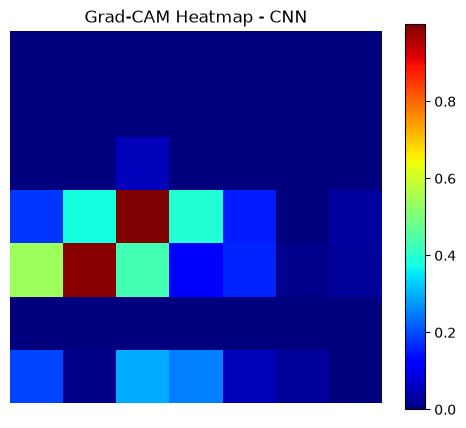

In [16]:

# 6. Build Grad-CAM model for our trained CNN

from tensorflow.keras.models import Model
from tensorflow.keras.layers import Input

# Create a new symbolic input
grad_input = Input(shape=(28, 28, 1))

x = grad_input
conv_output = None

# Pass input through existing trained layers
for layer in model.layers:

    x = layer(x, training=False)

    if layer.name == "conv2d_2":
        conv_output = x

# Check convolutional output
if conv_output is None:
    raise ValueError("Could not find conv2d_2 layer")

# Build Grad-CAM model
grad_model = Model(
    inputs=grad_input,
    outputs=[conv_output, x]
)

print("Grad-CAM model created successfully!")
print("Convolution output:", conv_output.shape)
print("Prediction output:", x.shape)


# Calculate Grad-CAM
with tf.GradientTape() as tape:

    conv_outputs, predictions = grad_model(
        input_batch,
        training=False
    )

    class_index = tf.argmax(predictions[0])

    class_score = predictions[:, class_index]

# Calculate gradients
grads = tape.gradient(class_score, conv_outputs)

# Global average pooling
pooled_grads = tf.reduce_mean(
    grads,
    axis=(0, 1, 2)
)

# Generate heatmap
conv_outputs = conv_outputs[0]

heatmap = tf.reduce_sum(
    conv_outputs * pooled_grads,
    axis=-1
)

heatmap = tf.maximum(heatmap, 0)

heatmap = heatmap / (
    tf.reduce_max(heatmap) + 1e-8
)

heatmap = heatmap.numpy()

# Display heatmap
plt.figure(figsize=(6, 5))
plt.imshow(heatmap, cmap="jet")
plt.title("Grad-CAM Heatmap - CNN")
plt.colorbar()
plt.axis("off")
plt.show()


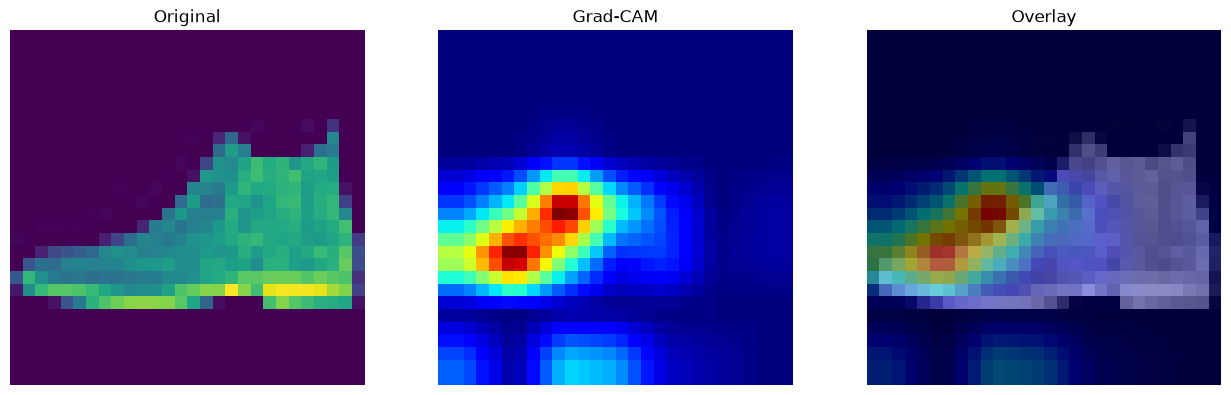

In [17]:
# 7. Resize and overlay Grad-CAM on the original image
heatmap_resized = cv2.resize(heatmap, (image.shape[1], image.shape[0]))
heatmap_uint8 = np.uint8(255 * heatmap_resized)
heatmap_color = cv2.applyColorMap(heatmap_uint8, cv2.COLORMAP_JET)
heatmap_color = cv2.cvtColor(heatmap_color, cv2.COLOR_BGR2RGB)

original_uint8 = np.uint8(np.clip(image, 0, 1) * 255)
overlay = cv2.addWeighted(original_uint8, 0.55, heatmap_color, 0.45, 0)

fig, axes = plt.subplots(1, 3, figsize=(13, 4))
axes[0].imshow(image)
axes[0].set_title("Original")
axes[1].imshow(heatmap_resized, cmap="jet")
axes[1].set_title("Grad-CAM")
axes[2].imshow(overlay)
axes[2].set_title("Overlay")
for ax in axes:
    ax.axis("off")
plt.tight_layout()
plt.show()


## Part B — Image segmentation

A segmentation mask separates the foreground object from the background. Fashion-MNIST has a nearly black background, so Otsu thresholding is a practical starting point. We then keep the largest foreground contour and clean small gaps with morphological operations.


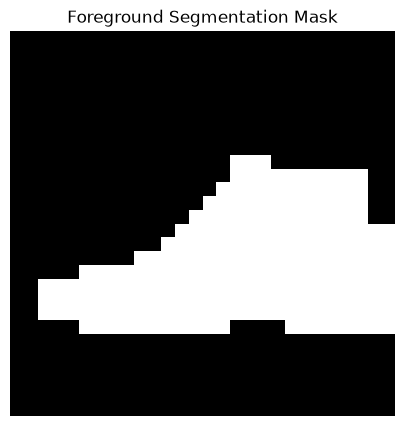

In [19]:

# 8. Create a binary foreground segmentation mask

# Convert image from (28, 28, 1) to (28, 28)
gray_image = image.squeeze()

# Convert pixel values to uint8 (0-255)
gray_image = np.uint8(np.clip(gray_image, 0, 1) * 255)

# Apply Otsu thresholding
_, mask = cv2.threshold(
    gray_image,
    0,
    255,
    cv2.THRESH_BINARY + cv2.THRESH_OTSU
)

# Remove small noise
kernel = np.ones((3, 3), np.uint8)

mask = cv2.morphologyEx(
    mask, cv2.MORPH_OPEN, kernel
)

# Fill small gaps
mask = cv2.morphologyEx(
    mask, cv2.MORPH_CLOSE, kernel
)

# Keep the largest foreground contour
contours, _ = cv2.findContours(
    mask,
    cv2.RETR_EXTERNAL,
    cv2.CHAIN_APPROX_SIMPLE
)

if contours:
    largest = max(contours, key=cv2.contourArea)

    clean_mask = np.zeros_like(mask)

    cv2.drawContours(
        clean_mask,
        [largest],
        -1,
        255,
        cv2.FILLED
    )

    mask = clean_mask

# Display segmentation mask
plt.figure(figsize=(5, 5))
plt.imshow(mask, cmap="gray")
plt.title("Foreground Segmentation Mask")
plt.axis("off")
plt.show()


RGBA shape: (28, 28, 4)


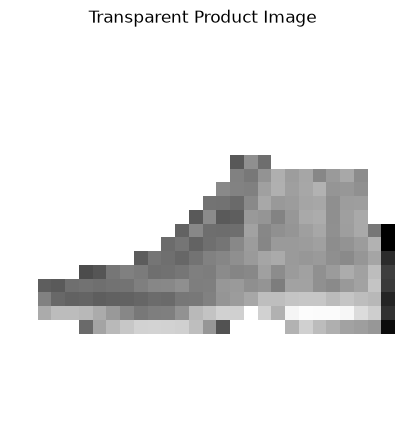

In [21]:

# 9. Create a transparent RGBA image

# Convert grayscale image into 2D format
gray = image.squeeze()

# Convert grayscale into RGB (3 channels)
rgb_image = np.stack([gray, gray, gray], axis=-1)

# Convert mask into alpha channel
alpha = mask.astype("float32") / 255.0

# Combine RGB + Alpha = RGBA
rgba = np.dstack([rgb_image, alpha])

print("RGBA shape:", rgba.shape)

# Display transparent image
plt.figure(figsize=(5, 5))
plt.imshow(rgba)
plt.title("Transparent Product Image")
plt.axis("off")
plt.show()


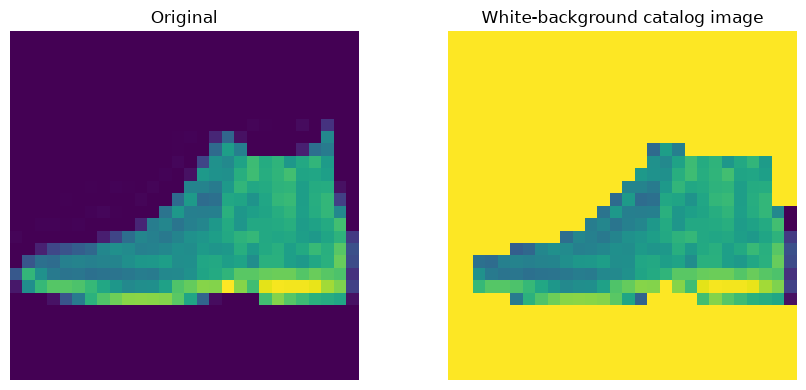

In [22]:
# 10. Create a white-background catalog image
white_background = np.full_like(original_uint8, 255)
alpha = (mask.astype("float32") / 255.0)[..., np.newaxis]
catalog_image = (
    original_uint8.astype("float32") * alpha
    + white_background.astype("float32") * (1 - alpha)
).astype("uint8")

fig, axes = plt.subplots(1, 2, figsize=(9, 4))
axes[0].imshow(image)
axes[0].set_title("Original")
axes[1].imshow(catalog_image)
axes[1].set_title("White-background catalog image")
for ax in axes:
    ax.axis("off")
plt.tight_layout()
plt.show()


## Part C — Save the generated outputs

The output folder is created in the project root. The files are saved as PNG images so they can be reused in later project stages.


In [23]:
# 11. Save Grad-CAM, mask, transparent image, and catalog image
OUTPUT_DIR = ROOT / "Outputs" / "Day-08"
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

cv2.imwrite(str(OUTPUT_DIR / "gradcam_heatmap.png"), heatmap_uint8)
cv2.imwrite(str(OUTPUT_DIR / "segmentation_mask.png"), mask)
cv2.imwrite(
    str(OUTPUT_DIR / "transparent_product.png"),
    cv2.cvtColor(rgba, cv2.COLOR_RGBA2BGRA)
)
cv2.imwrite(
    str(OUTPUT_DIR / "catalog_white_background.png"),
    cv2.cvtColor(catalog_image, cv2.COLOR_RGB2BGR)
)

print("Saved output files to:", OUTPUT_DIR)
for file_path in sorted(OUTPUT_DIR.glob("*.png")):
    print("-", file_path.name)


Saved output files to: D:\RetailMind-AI\Outputs\Day-08
- catalog_white_background.png
- gradcam_heatmap.png
- segmentation_mask.png
- transparent_product.png


## Part D — Optional: GrabCut for natural product images

GrabCut is useful when working with a real product photograph that has a more complex background. It needs a rectangle that roughly contains the foreground object. It may not outperform the thresholding approach on Fashion-MNIST's simple black background.

To use this on another image, load an RGB product photo, convert it to BGR for OpenCV, and adjust the rectangle so it surrounds the product.


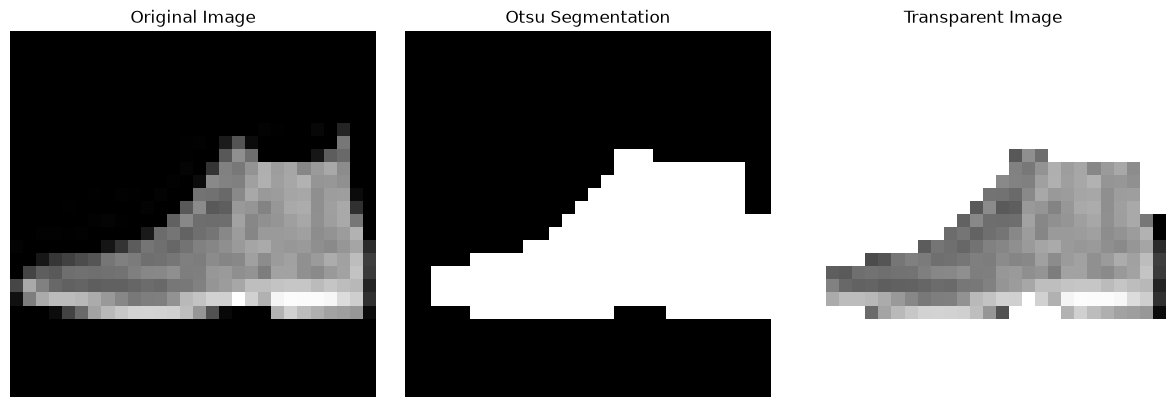

Segmentation pixel values: [  0 255]
Foreground pixels: 221
Background pixels: 563


In [25]:

# 12. Compare segmentation techniques

fig, axes = plt.subplots(1, 3, figsize=(12, 4))

axes[0].imshow(image.squeeze(), cmap="gray")
axes[0].set_title("Original Image")

axes[1].imshow(mask, cmap="gray")
axes[1].set_title("Otsu Segmentation")

axes[2].imshow(rgba)
axes[2].set_title("Transparent Image")

for ax in axes:
    ax.axis("off")

plt.tight_layout()
plt.show()

print("Segmentation pixel values:", np.unique(mask))
print("Foreground pixels:", np.sum(mask == 255))
print("Background pixels:", np.sum(mask == 0))
